# **Car Price Analysis EDA**

## Objectives

* Find relationships between features and target, form hypotheses, create visualisations to support them, then statistically test them to determine significance.

## Inputs

* Clean data CSV (data/cleaned data/car_price_cleaned.csv)
* Data dictionary (data/rawdata/data_dictionary.csv )

## Outputs

* Visualisations
* Statistical test results 

## Additional Comments

* We will form and test hypotheses to determine which features significantly affect the target.



---

## Import libraries

In [2]:
import pandas as pd
import numpy as np
import pingouin as pg
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
# last line of code generated by Gemini in Project 1 (E Hemraj) to allow matplotlib plots to be seen

## Change working directory

We need to change the working directory from its current folder to its parent folder
* We access the current directory with os.getcwd()

In [3]:
import os
current_dir = os.getcwd()
current_dir

'c:\\Users\\world\\Documents\\CI VS Code Projects\\Capstone Projects\\Car-Price-Analysis\\jupyter_notebooks'

We want to make the parent of the current directory the new current directory
* os.path.dirname() gets the parent directory
* os.chir() defines the new current directory

In [4]:
os.chdir(os.path.dirname(current_dir))
print("You set a new current directory")

You set a new current directory


Confirm the new current directory

In [5]:
current_dir = os.getcwd()
current_dir

'c:\\Users\\world\\Documents\\CI VS Code Projects\\Capstone Projects\\Car-Price-Analysis'

## Load Cleaned Data

In [6]:
# code changed from Gemini
df = pd.read_csv('data/cleaned data/car_price_cleaned.csv')

df.shape

(205, 27)

In [7]:
# check the first 5 rows to see if it has loaded correctly
df.head()

,car_id,symboling,car_name,fuel_type,aspiration,door_number,body_style,drive_wheel,engine_location,wheel_base,...,fuel_system,bore_ratio,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price,brand
0,1,3,alfa-romero giulia,gas,std,2,convertible,rwd,front,88.6,...,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0,alfa-romeo
1,2,3,alfa-romero stelvio,gas,std,2,convertible,rwd,front,88.6,...,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0,alfa-romeo
2,3,1,alfa-romero Quadrifoglio,gas,std,2,hatchback,rwd,front,94.5,...,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0,alfa-romeo
3,4,2,audi 100 ls,gas,std,4,sedan,fwd,front,99.8,...,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0,audi
4,5,2,audi 100ls,gas,std,4,sedan,4wd,front,99.4,...,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0,audi


### Dataset Context & Units

This dataset was downloaded from Kaggle. It contains records for 205 cars from the *1985 Ward's Automotive Yearbook*, hosted on the UCI Machine Learning Repository (donated in 1987).

Standard US units used in this notebook:
- **Price:** US Dollars ($)
- **Horsepower:** hp
- **Curb Weight:** Pounds (lbs)
- **Engine Size:** Cubic inches (cu in)
- **Fuel Economy:** Miles per gallon (mpg)
- **Dimensions (wheel base, length, width, height):** Inches (in)

See `data/raw data/data_dictionary.csv` for column descriptions and the link to the UCI repository page.

AI Usage Note: Generative AI was used for language refinement.

## Describe the Data

We will describe the data to check that the ranges and average values look realistic.

In [8]:
df.describe()

,car_id,symboling,door_number,wheel_base,car_length,car_width,car_height,curb_weight,cylinder_number,engine_size,bore_ratio,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,3.121951,98.756585,174.049268,65.907805,53.724878,2555.565854,4.380488,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,0.994966,6.021776,12.337289,2.145204,2.443522,520.680204,1.080854,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,2.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,2.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,4.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,4.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,4.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,4.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,4.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,4.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,12.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


AI Note: Gemini was used to understand automotive terms like symboling and compression ratio and to help with insights.

There are a few things to note from this description:
- We can ignore the stats for `car_id` as it is a column that tracks the identity of each car.
- All physical measurements are positive (no negative or 0 values).
- `door_number` and `cylinder_number` are within the correct ranges.
- There are negative values in `symboling`, however, it is a measure for safety which ranges from -3 to 3, so the values are valid.
- `price` varies significantly, with a jump from the 75th percentile to the maximum price. The mean value is also higher than the median, perhaps due to the presence of luxury cars in the dataset.
- There is another significant jump from the 75th percentile to the maximum value in `horsepower`, `curb_weight` and `engine_size`.
- The maximum value in `compression_ratio` could be due to the presence of diesel cars.

The data looks accurate and clean. In this notebook we will explore relationships between variables and the target.

## Core statistical concepts

- Mean: This is a value that is calculated by adding up all the values within a category, then dividing by the number of values there are in the category.

- Median: This is a value that is calculated by lining up all values within a category from smallest to largest, then taking the value that is the middle value in this line. (If there are an even number of values, the median is calculated by finding the midway number between thoise values).

- Normal Distribution: This is when data clusters in a symmetric way around the average, resulting in a bell shaped curve on a graph.

- Standard Deviation: This is a measure of how much data points spread around the mean. A low standard deviation means data clusters more around the mean.

- 25% / Q1: The 25th percentile or first quartile is the mark for the bottom quarter of the data, lined up from the minimum to the maximum value. 25% of the data sits below this.

- 50% / Q2: The 50th percentile or second quartile is the midway mark (the median). 50% of the data sits above this and 50% below this.

- 75% / Q3: The 75th percentile or third quartile is the mark for the top quarter of the data. 75% of the data points sit below this.

- IQR: The interquartile range is the distance between Q1 and Q3. It is where the middle 50% of the data sits.

- Hypothesis Testing: After forming hypotheses, in order to evaluate whether relationships mentioned within them are significant, they must be statistically tested. The result of the test will determine whether the null hypothesis (there is no significant relationship) is accepted or rejected in favour of the alternative hypothesis (there is significance). Different statistical tests are used in different situations, e.g. when comparing 2 things or 3 things or when the data is not normally distributed to when it is etc.

We will refer to some of these concepts in this notebook.

## Outlier Check

We will inspect the distribution of our target variable, `price`, to check for potential outliers. In our summary statistics in the ETL Notebook, prices ranged from $5,118 to $45,400, with a jump from the 75th percentile to the maximum value. We will use a box plot to visualise this distribution and see whether high-end values represent data errors or legitimate luxury vehicles.

AI Usage Note: Generative AI was used for language refinement.

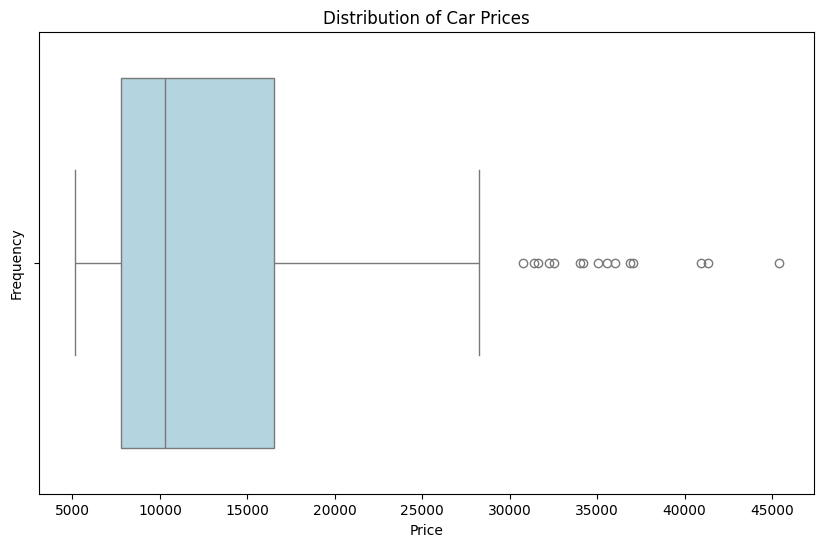

In [9]:
# Gemini and copilot prediction used in this code
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='price', color='lightblue')
plt.title('Distribution of Car Prices')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

### Observations

- Threshold: The box plot shows several data points sitting beyond the upper whisker ($Q3 + 1.5 \times \text{IQR}$, around $28,000), which technically marks them as outliers.

- Distribution Pattern: Rather than one isolated point, the values above the upper whisker increase gradually across the $30,000 to $45,000+ range. This steady spread supports the idea that these are not data entry errors.   

- Business Decision: These higher prices represent genuine luxury or high performance cars in the market. As they reflect real-world data, all values will be kept for our hypotheses testing and analyses.

(Q3 is the mark for the top quarter of the data. 75% of the data points sit below this. The IQR is the distance between Q1 and Q3. It is where the middle 50% of the data sits).

AI Usage Note: Generative AI was used for grammar and language refinement to assist in drafting this summary based on my findings and conclusions.

## Business Hypotheses Considerations

Our hypotheses will focus on factors affecting car price, as this is the target we have identified from the project goals for this dataset in Unit 2. We will later train a machine learning prediction model based on this target. Inspecting our data and looking carefully at the summary statistics for each column gives us a few key features that may relate to car prices.

We can plot a heatmap to see the relationship between price and other numerical columns, then use our findings to guide our hypotheses.



In [10]:
# we will check how many numerical columns are in our dataset
# code from Gemini
df.select_dtypes(include='number').columns

Index(['car_id', 'symboling', 'door_number', 'wheel_base', 'car_length',
       'car_width', 'car_height', 'curb_weight', 'cylinder_number',
       'engine_size', 'bore_ratio', 'stroke', 'compression_ratio',
       'horsepower', 'peak_rpm', 'city_mpg', 'highway_mpg', 'price'],
      dtype='object')

In [11]:
# we will calculate the correlation matrix to see how the numerical features are correlated with each other and save it in a variable
# we will drop the 'car_id' column
# coded with help from Gemini
corr_matrix = df.select_dtypes(include='number').drop(columns=['car_id']).corr()

<Axes: >

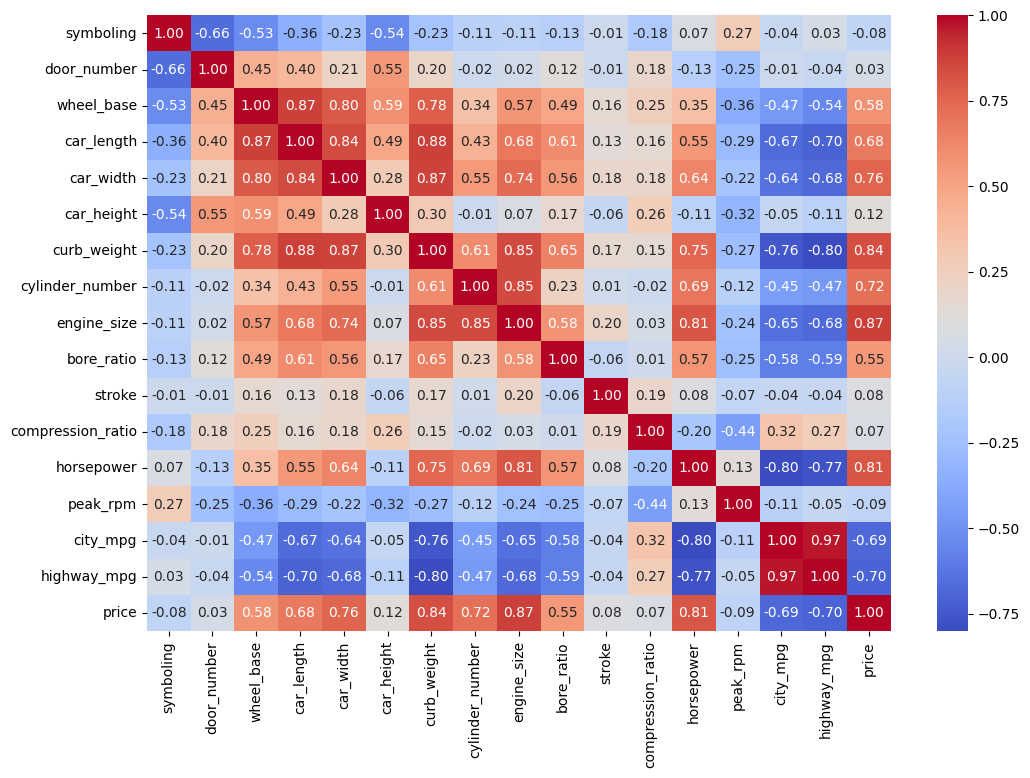

In [12]:
# we will plot a heatmap of the correlations
# Copilot predictions used to generate code
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f") 

### Observations

- The correlation matrix score ranges from 1 to -1. A score of 0 indicates no correlation. Values closer to 1 show a strong positive relationship, while values closer to -1 show a strong inverse relationship.  
 
- The heatmap reveals that the features most strongly correlated with price are `engine_size`, `curb_weight`, `horsepower`, `car_width`, `cylinder_number`, `highway_mpg`, `city_mpg`, and `car_length`. While most of these have positive correlations with price, `highway_mpg` and `city_mpg` have strong negative correlations. This makes sense as larger engines and heavier cars require more fuel to run, leading to lower MPG. Our hypotheses will focus directly on engine and body specifications rather than tracking MPG separately.  

AI Usage Note: Generative AI was used for grammar and language refinement to assist in drafting this summary based on my findings and conclusions.

We will look at the categorical columns quickly to see where the greatest differences lie before we finalise our hypotheses. We will do this by creating a variable with all the categorical columns, then looping through them and plotting each column against price.

In [13]:
# save categorical columns to a variable, dropping 'car_name' for cleaner plots
# code generated with help from Gemini
cat_cols = df.select_dtypes(include='object').drop(columns=['car_name']).columns

In [14]:
# check how many columns are categorical (excluding 'car_name')
len(cat_cols)

8

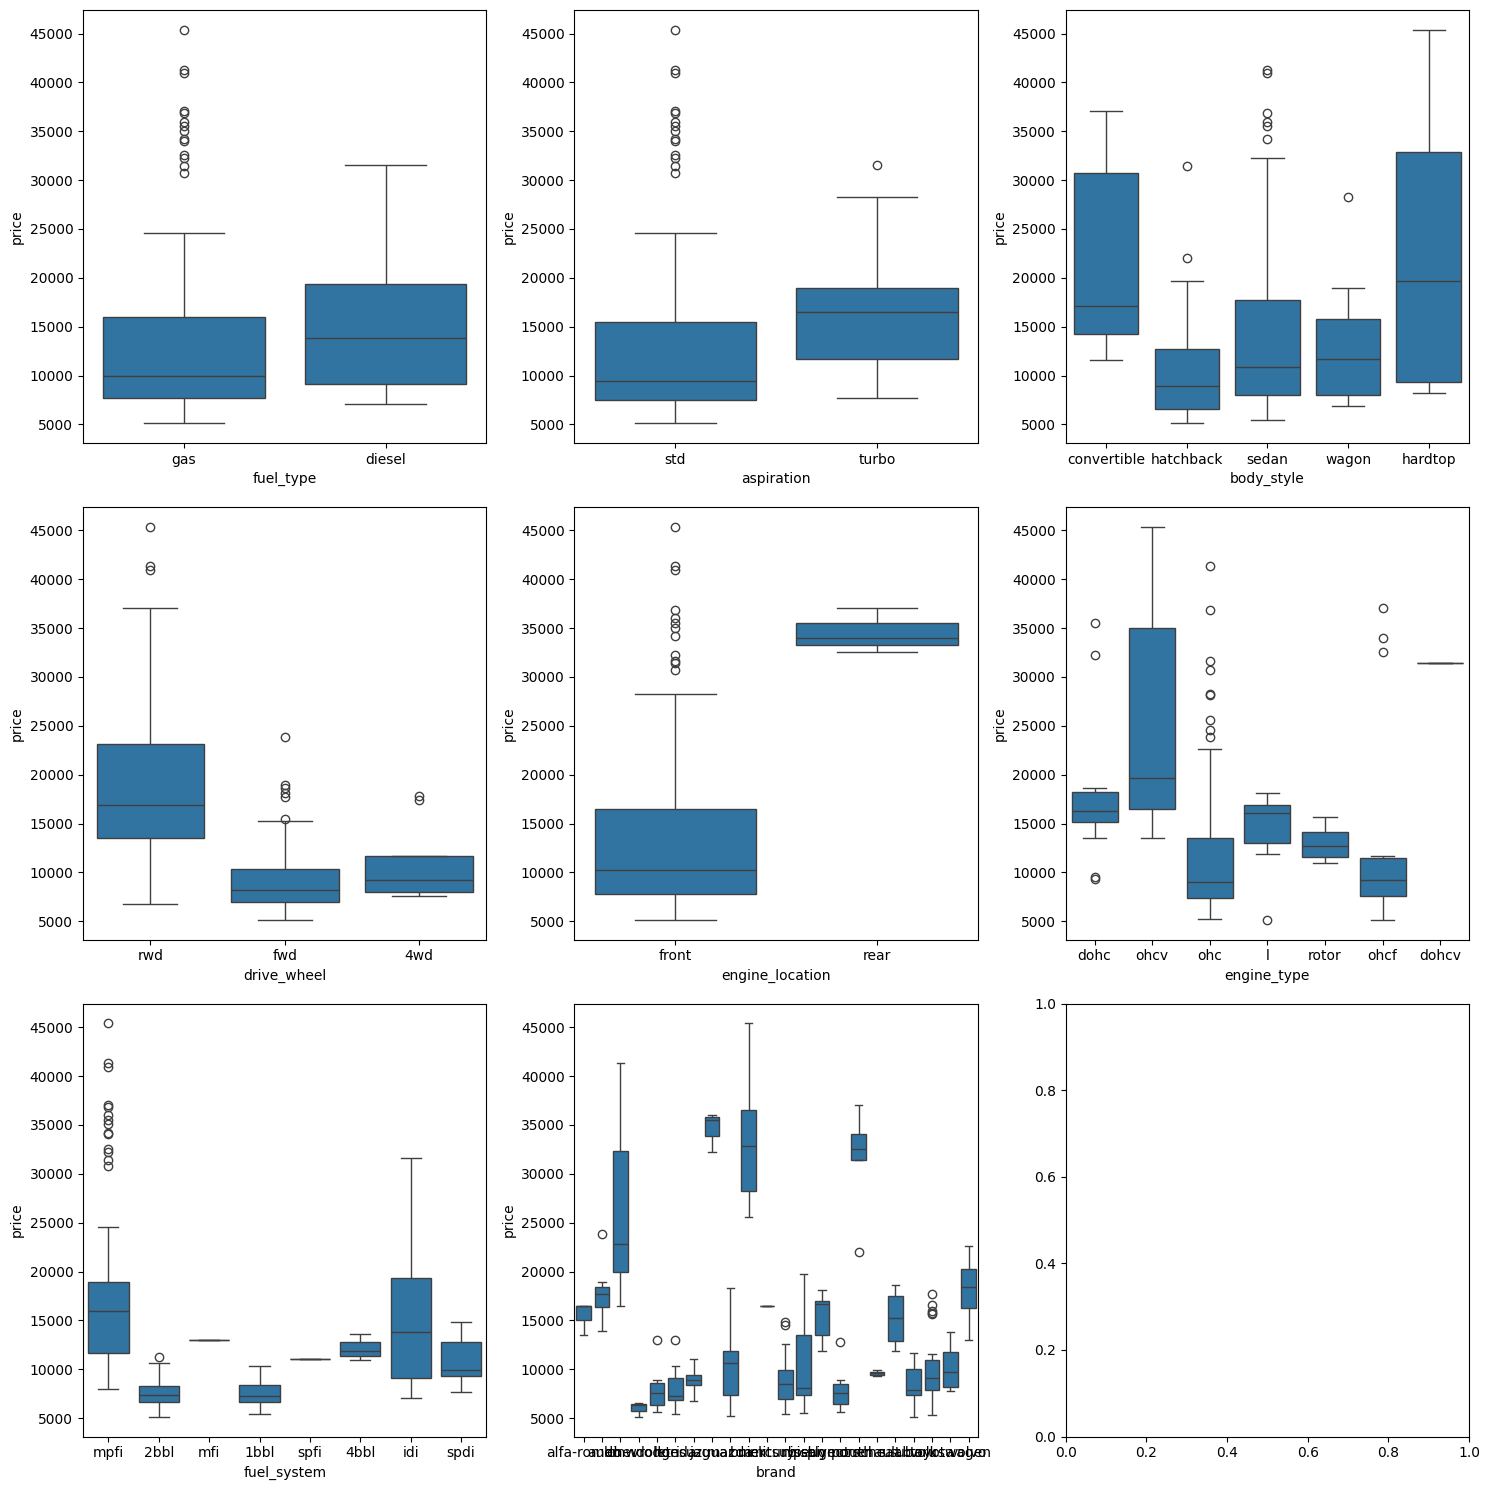

In [15]:
# we will loop through the categorical variables and create bar plots for each one
# code created with Gemini
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(15, 15))
axes = axes.flatten()

for index, col in enumerate(cat_cols):
    sns.boxplot(data=df, x=col, y='price', ax=axes[index])

plt.tight_layout()
plt.show()

### Observations

We plotted all the categorical features against price to identify what drives price and what we will leave out of our hypotheses.
 
**What we will exclude from our main hypotheses:** 
- `fuel_type` and `aspiration`: While turbo engines and diesel cars have a higher median price, standard engines and gas cars span the entire price spectrum with severe luxury outliers, making these features inconsistent for explaining pricing.
- `engine_location`, `engine_type` and `fuel_system`: These categories suffer from heavy imbalance. For example, only 3 cars in the entire dataset have rear engines, and some fuel systems and engine types appear only once, making them unsuitable for reliable statistical testing.
- `body_style`: There is overlap between body styles and some categories have much smaller sample sizes than others.

**What we will consider for our main hypotheses:** 
- `drive_wheel`: Rear-wheel drive (`rwd`) shows a big price difference compared to `fwd` and there is a large sample size for both. Four-wheel drive (`4wd`) accounts for only 9 vehicles, so it is excluded.
-  `brand`: There are brands present in our dataset that sit at the top of the price range ($30k+). We will test whether luxury brands have significantly higher prices than mainstream brands, while separately observing whether those premium cars also carry the larger engines and drive systems identified earlier.

We will form our hypotheses based on engine and size specs, drive-wheel and brand.

AI Usage Note: Generative AI was used to assist in phrasing refinement and structure formatting for these observations.





In [16]:
# verify category distributions for features flagged during visual inspection
# code from Gemini
imbalanced_cols = [ 'drive_wheel', 'body_style', 'engine_location', 'engine_type', 'fuel_system']

for col in imbalanced_cols:
    print(f"--- Value Counts: {col} ---")
    print(df[col].value_counts())
    print()

--- Value Counts: drive_wheel ---
drive_wheel
fwd    120
rwd     76
4wd      9
Name: count, dtype: int64

--- Value Counts: body_style ---
body_style
sedan          96
hatchback      70
wagon          25
hardtop         8
convertible     6
Name: count, dtype: int64

--- Value Counts: engine_location ---
engine_location
front    202
rear       3
Name: count, dtype: int64

--- Value Counts: engine_type ---
engine_type
ohc      148
ohcf      15
ohcv      13
dohc      12
l         12
rotor      4
dohcv      1
Name: count, dtype: int64

--- Value Counts: fuel_system ---
fuel_system
mpfi    94
2bbl    66
idi     20
1bbl    11
spdi     9
4bbl     3
mfi      1
spfi     1
Name: count, dtype: int64



## Business Hypotheses

**Hypothesis 1 (Engine Specs)**  
Null Hypothesis ($H_0$): There is no correlation between engine size/horsepower and car price.  
Alternative Hypothesis ($H_1$): There is a statistically significant correlation between engine size/horsepower and car price.  

---

**Hypothesis 2 (Car Size & Weight)**  
Null Hypothesis ($H_0$): There is no correlation between curb weight/car length and car price.  
Alternative Hypothesis ($H_1$): There is a statistically significant correlation between curb weight/car length and car price.  

---

**Hypothesis 3 (Drive-Wheel)**  
Null Hypothesis ($H_0$): There is no difference in price between rear-wheel drive and front-wheel drive cars.  
Alternative Hypothesis ($H_1$): There is a statistically significant difference in price between rear-wheel drive and front-wheel drive cars.  

---

**Hypothesis 4 (Brand)**  
Null Hypothesis ($H_0$): There is no difference in price between luxury brands and mainstream brands.  
Alternative Hypothesis ($H_1$): There is a statistically significant difference in price between luxury brands and mainstream brands.  

AI Usage Note: Generative AI was used as a language refinement and markdown tool to assist in drafting these hypotheses.

## Hypothesis Testing

After forming hypotheses, in order to evaluate whether relationships mentioned within them are significant, they must be statistically tested. The result of the test will determine whether the null hypothesis (there is no significant relationship) is accepted or rejected in favour of the alternative hypothesis (there is significance). Different statistical tests are used in different situations, e.g. when comparing 2 things or 3 things or when the data is not normally distributed to when it is etc.

### **Hypothesis 1:**

Null Hypothesis ($H_0$): There is no correlation between engine size/horsepower and car price.  
Alternative Hypothesis ($H_1$): There is a statistically significant correlation between engine size/horsepower and car price.

We will create 2 scatter plots of engine size against price and horsepower against price.

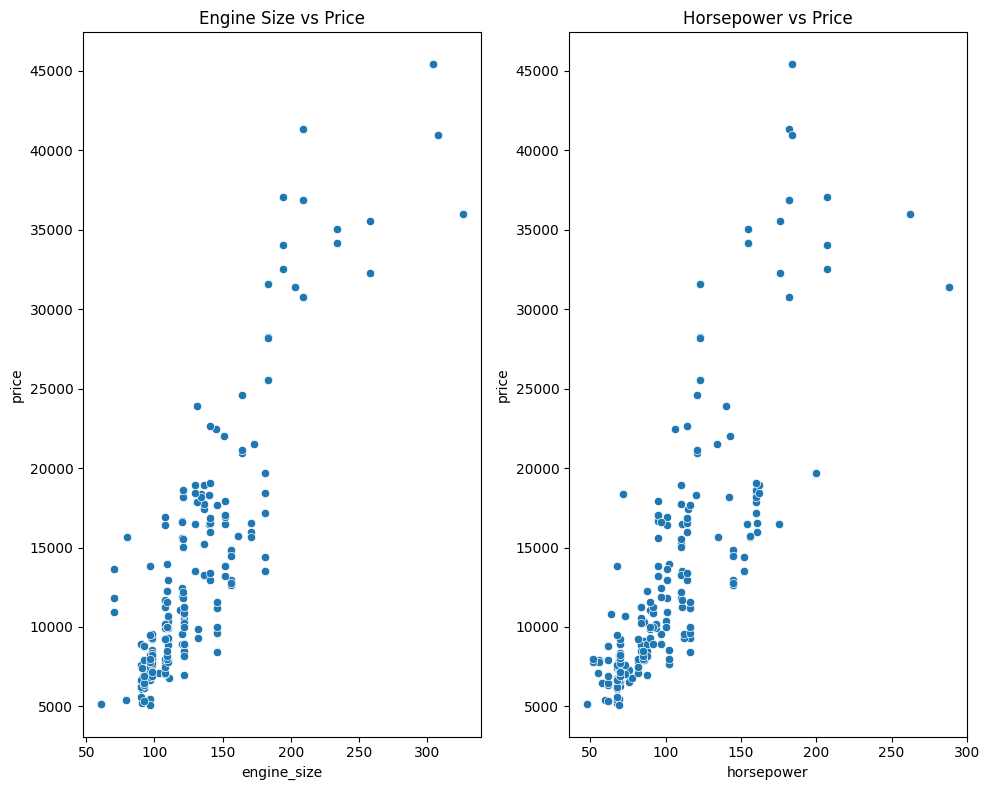

In [17]:
# code adapted from Gemini
# Copilot predictions used

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10,8))

engine_features = ['engine_size', 'horsepower']

for index, col in enumerate(engine_features):
    sns.scatterplot(data=df, x=col, y='price', ax=axes[index])
    axes[index].set_title(f'{col.replace("_", " ").title()} vs Price')
    axes[index].set_xlabel(col)
    axes[index].set_ylabel('price')

plt.tight_layout()
plt.show()


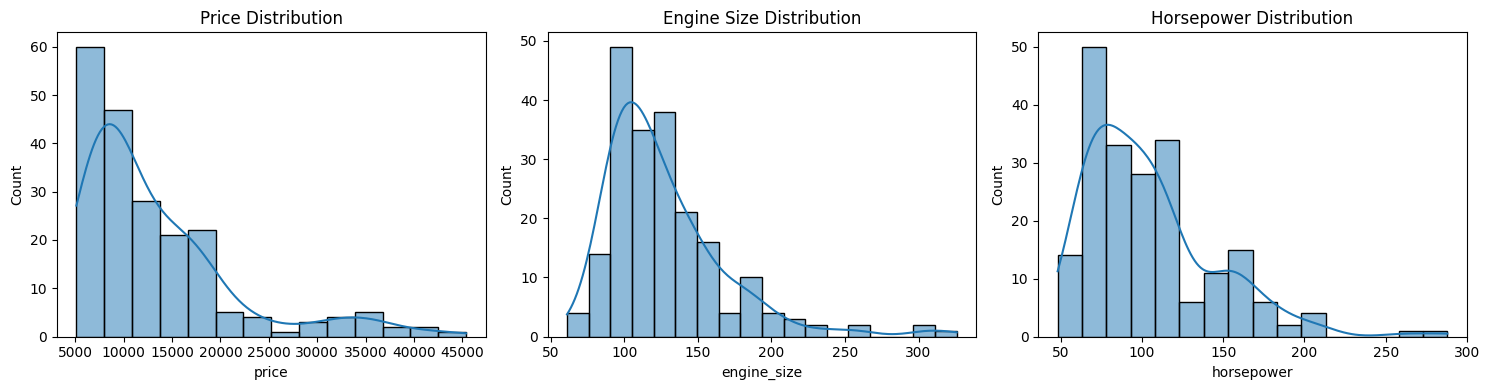

In [18]:
# we will check the distribution of 'price', 'engine_size' and 'horsepower' before drawing insights.
# code adapted from Gemini with use of Copilot predictions

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 4))

dist_cols = ['price', 'engine_size', 'horsepower']

for index, col in enumerate(dist_cols):
    sns.histplot(data=df, x=col, kde=True, ax=axes[index])
    axes[index].set_title(f'{col.replace("_", " ").title()} Distribution')

plt.tight_layout()
plt.show()

### Observations

- All three variables (`price`, `engine_size`, and `horsepower`) look right-skewed, with most of the data clustered on the left and long tails stretching to the right. Most cars have engine sizes under 150, horsepower under 120, and prices under $15,000. We will take into consideration the shape of the histograms when we conduct statistical tests.

- Both engine size and horsepower show a general positive trend with price, meaning cars with larger engines and higher horsepower generally cost more. Their scatter plots look very similar, reflecting their strong correlation with each other (~0.81) as well as with price.

- Price spread is present across all performance levels and widens at higher spec levels where there are fewer cars. 

- Due to the price spread across both scatter plots, engine size and horsepower alone cannot reliably determine vehicle price without additional factors, and the visual trend must be statistically tested to determine significance.

AI Usage Note: Generative AI was used as a grammar and language refinement tool to assist in drafting these visual insights.


### Statistical Tests for Hypothesis 1

We want to determine whether a statistically significant relationship exists between `price` and engine specs like `engine_size` and `horsepower`. As they are all coninuous variables, we will do a correlation test. Before deciding which type of correlation test to do, we must check for distribution. We will not rely on the histograms alone, but will do a Shapiro-Wilk test for distribution. If the data is normally distributed, we can do a Pearson correlation test, if not, we will do a Spearman rank correlation test.

Normal Distribution: This is when data clusters in a symmetric way around the average, resulting in a bell shaped curve on a graph.

AI Usage Note: Generative AI was used in addition to the LMS to understand which tests are suitable for numerical variables.

In [19]:
# code adapted from LMS: Shapiro-Wilk Normality Test
# test normality across all three numerical features at alpha = 0.05
# Gemini used to help adapt code
normality_results = pg.normality(data=df[['price', 'engine_size', 'horsepower']], alpha=0.05)
normality_results

# alpha was set to 0.05 as this is a common threshold for statistical significance in hypothesis testing. It means that we are willing to accept a 5% chance of incorrectly rejecting the null hypothesis (i.e., concluding that the data is not normally distributed when it actually is).
# Copilot prediction used to complete above explanation

,W,pval,normal
price,0.800665,1.849093e-15,False
engine_size,0.829439,3.056836e-14,False
horsepower,0.883624,1.736468e-11,False


We see that the data does not have a normal distribution. Therefore, we will choose to do a Spearman rank correlation test.

In [20]:
# code taken from Gemini
# Spearman rank correlation

# Test correlation between engine_size and price
corr_engine = pg.corr(x=df['engine_size'], y=df['price'], method='spearman')

# Test correlation between horsepower and price
corr_hp = pg.corr(x=df['horsepower'], y=df['price'], method='spearman')

display(corr_engine)
display(corr_hp)

,n,r,CI95,p_val,power
spearman,205,0.825996,"[0.78, 0.87]",1.943726e-52,1.0


,n,r,CI95,p_val,power
spearman,205,0.85461,"[0.81, 0.89]",1.096765e-59,1.0


### Hypothesis 1 Conclusion:

**Null Hypothesis** ($H_0$): There is no significant relationship between engine size/horsepower and price ($r = 0$).  
Alternative Hypothesis ($H_1$): There is a statistically significant relationship between engine size/horsepower and price ($r \neq 0$).  
Significance Threshold: $\alpha = 0.05$

Test Results: 

Engine Size vs. Price:  
Spearman Correlation ($r$): $0.826$  
p-value: $1.94 \times 10^{-52}$

Horsepower vs. Price:  
Spearman Correlation ($r$): $0.855$  
p-value: $1.10 \times 10^{-59}$

Decision:
Both p-values are much smaller than 0.05 and the correlation coefficients ($r$) are close to 1, showing a strong positive relationship.
Horsepower has a slightly stronger correlation than engine size with price.
Based on r and p values, we reject the null hypothesis and accept the alternative hypothesis that there is a statistically significant relationship between engine size and price as well as between horsepower and price.

AI Usage Note: Generative AI was used for markdown and to help interpret the correlation coefficient and p value result.

### **Hypothesis 2:**

Null Hypothesis ($H_0$): There is no correlation between curb weight/car length and car price.  
Alternative Hypothesis ($H_1$): There is a statistically significant correlation between curb weight/car length and car price.  

We will create 2 join plots of curb weight against price and car length against price.

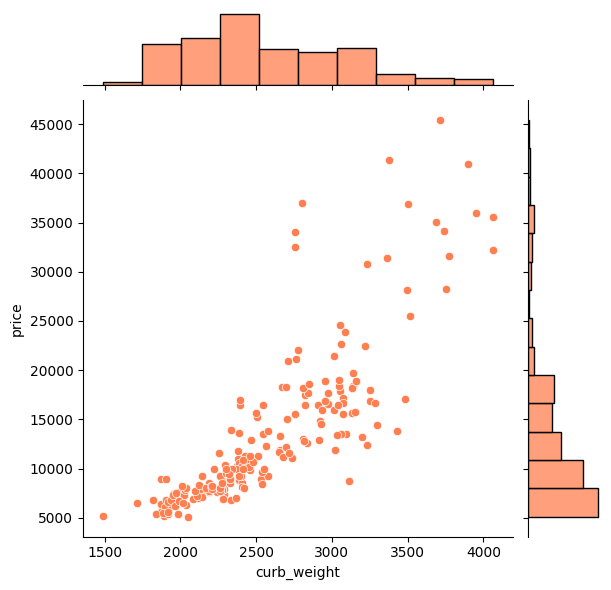

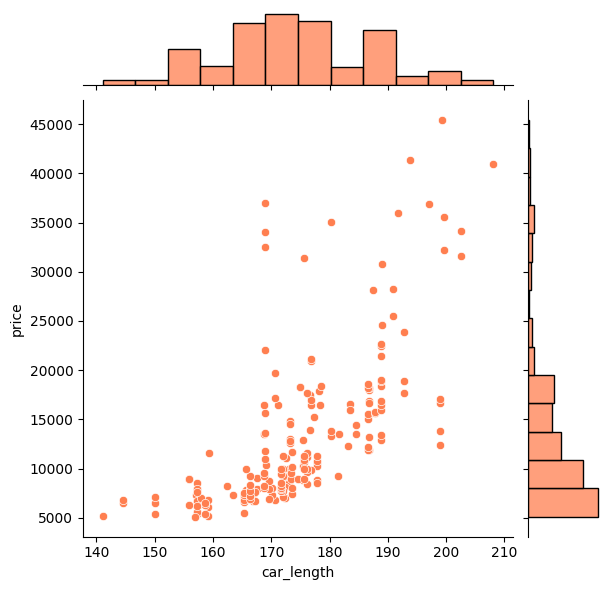

In [21]:
# Code adapted from Gemini

physical_features = ["curb_weight", "car_length"]

for col in physical_features:
    sns.jointplot(
        data=df,
        x=col,
        y="price",
        color="coral"  # e.g., 'teal', 'darkcyan', 'coral'
    )
    plt.show()

### Observations

- There is a positive relationship between the curb weight and price, as well as between car length and price. As a car's weight and length increase, price tends to increase.

- There is clustering towards the lower price points with lower specs, and we see more price variation as the specs increase. 

- We will check the normality of distribution for `curb_weight` and `car_length`, although as we have already tested price and know that it does not have a normal distribution, we will be conducting a Spearman rank correlation test for hypothesis 2.


### Statistical Tests for Hypothesis 2

In [22]:
# code adapted from LMS: Shapiro-Wilk Normality Test
# test normality across all three numerical features at alpha = 0.05
# Gemini used to help adapt code
normality_results = pg.normality(data=df[['price', 'curb_weight', 'car_length']], alpha=0.05)
normality_results

,W,pval,normal
price,0.800665,1.849093e-15,False
curb_weight,0.953042,2.891342e-06,False
car_length,0.982095,1.035992e-02,False


We will now conduct a Spearman rank correlation test.

In [23]:
# Code adapted from Gemini
# Spearman rank correlation

# Test correlation between curb_weight and price
corr_weight = pg.corr(
    x=df["curb_weight"],
    y=df["price"],
    method="spearman",
)

# Test correlation between car_length and price
corr_length = pg.corr(
    x=df["car_length"],
    y=df["price"],
    method="spearman",
)

display(corr_weight)
display(corr_length)

,n,r,CI95,p_val,power
spearman,205,0.909067,"[0.88, 0.93]",4.002611e-79,1.0


,n,r,CI95,p_val,power
spearman,205,0.804316,"[0.75, 0.85]",8.905308e-48,1.0


### Hypothesis 2 Conclusion:

**Null Hypothesis** ($H_0$): There is no correlation between curb weight/car length and car price.  
Alternative Hypothesis ($H_1$): There is a statistically significant correlation between curb weight/car length and car price.  
Significance Threshold: $\alpha = 0.05$

Test Results: 

Curb Weight vs. Price:  
Spearman Correlation ($r$): $0.909$  
p-value: $4.00 \times 10^{-79}$

Car Length vs. Price:  
Spearman Correlation ($r$): $0.804$  
p-value: $8.91 \times 10^{-48}$

Decision:
Both p-values are much smaller than 0.05 and the correlation coefficients ($r$) are close to 1, showing a strong positive relationship.
Curb weight has a stronger correlation than car length to price.
Based on r and p values, we reject the null hypothesis and accept the alternative hypothesis that there is a statistically significant correlation between curb weight and price as well as between car length and price.

NB: As bigger engines are usually heavier and need a larger, stronger car frame to support them, it is natural that if engine sizes increase in this dataset, car weight would also increase. Both show a link to higher car prices.

AI Usage Note: Generative AI was used for markdown and to help interpret the correlation coefficient and p value result.

### **Hypothesis 3 (Drive-Wheel)** 
 
Null Hypothesis ($H_0$): There is no difference in price between rear-wheel drive and front-wheel drive cars.  
Alternative Hypothesis ($H_1$): There is a statistically significant difference in price between rear-wheel drive and front-wheel drive cars.  

We will look at the descriptive statistics for `drive_wheel` to see average prices.

In [24]:
# code from Gemini
df.groupby('drive_wheel')['price'].describe()

,count,mean,std,min,25%,50%,75%,max
drive_wheel,,,,,,,,
4wd,9.0,11087.463000,3988.644756,7603.0,8013.00,9233.0,11694.0,17859.167
fwd,120.0,9239.308333,3317.930730,5118.0,6976.25,8222.0,10307.5,23875.000
rwd,76.0,19910.809211,9120.137883,6785.0,13475.00,16912.5,23110.0,45400.000


### Observations

- Looking at the median is more reliable than comparing the mean, as high maximum prices (that are a jump from the 75th percentile) pull the mean up. The median for rwd is $16,912.50, whereas the maximum price is $45,400. The median for fwd is $8,222, with the maximum at $23,875.

- As price is not normally distributed, we will conduct a non-parametric test to compare rear_wheel drive and front_wheel drive cars: the Mann-Whitney U test. To do this, we will create 2 groups: group 1 will be the prices of each rwd car, and group 2 will contain all the prices of fwd cars. The test will rank them and calculate how many times a rwd car outranked fwd cars and vice versa, resulting in a U score. A similar U score for both groups would mean there is no significant difference, though the p-value will technically determine whether the difference is statistically significant.

- Mean: This is a value that is calculated by adding up all the values within a category, then dividing by the number of values there are in the category.

- Median: This is a value that is calculated by lining up all values within a category from smallest to largest, then taking the value that is the middle value in this line. (If there are an even number of values, the median is calculated by finding the midway number between thoise values).

AI Usage Note: Generative AI was used to help understand how the Mann-Whitney U test compares groups.

### Statistical Tests for Hypothesis 3

In [25]:
# code from Gemini
# isolate prices for rear-wheel drive
rwd_prices = df[df['drive_wheel'] == 'rwd']['price']

# isolate prices for front-wheel drive
fwd_prices = df[df['drive_wheel'] == 'fwd']['price']

# run the Mann-Whitney U test
mwu_result = pg.mwu(x=rwd_prices, y=fwd_prices)
mwu_result

,U_val,alternative,p_val,RBC,CLES
MWU,8295.5,two-sided,4.783170e-22,0.819189,0.909594


### Hypothesis 3 Conclusion:

Null Hypothesis ($H_0$): There is no difference in price between rear-wheel drive and front-wheel drive cars.  
Alternative Hypothesis ($H_1$): There is a statistically significant difference in price between rear-wheel drive and front-wheel drive cars.
Significance Threshold: $\alpha = 0.05$

Test Results:

Rear-Wheel Drive vs. Front-Wheel Drive:  
Mann-Whitney U ($U$): 8295.5  
p-value: $4.78 \times 10^{-22}$  
Common Language Effect Size (CLES): 0.910 (91.0%)  
Group Medians: RWD = $16,912.50 | FWD = $8,222.00

Decision: The p-value ($4.78 \times 10^{-22}$) is far below 0.05, and the CLES of 0.910 indicates a 91.0% probability that a randomly selected rear-wheel drive car is more expensive than a front-wheel drive car. Rear-wheel drive cars have a considerably higher median price ($16,912.50) compared to front-wheel drive cars ($8,222.00). Based on these results, we reject the null hypothesis and accept the alternative hypothesis that there is a statistically significant difference in price between rear-wheel drive and front-wheel drive cars.

NB: The U score belongs to the 'rwd' group as it was passed first. We could reverse the order to see the U score for the 'fwd' group, but it is the p_value that decides whether the difference is significant or not. Since the p_value does not change, no matter the argument order, our decision remains the same.

AI Usage Note: Generative AI was used for markdown and to help interpret the Mann-Whitney U test result.

### **Hypothesis 4 (Brand)** 
 
Null Hypothesis ($H_0$): There is no difference in price between luxury brands and mainstream brands.  
Alternative Hypothesis ($H_1$): There is a statistically significant difference in price between luxury brands and mainstream brands. 

We want to test whether vehicle prices differ significantly between luxury and mainstream manufacturers. We will use a similar method to hypothesis 3 as we are evaluating the price difference within a categorical feature.

We will classify the manufacturers into two groups: luxury and mainstream. While separating brands involves an element of subjectivity in where the threshold is drawn, we will inspect the brand value counts and an enlarged box plot of prices by brand to establish a clear, data-informed boundary.

Once grouped, we will calculate group medians and run a Mann-Whitney U test to evaluate whether the price difference between the two tiers is statistically significant.

AI Usage Note: Generative AI was used as a language and grammar tool.

In [26]:
# we will run value counts then plot the box plot from earlier in a bigger space to see all the brands

df['brand'].value_counts()


brand
toyota        32
nissan        18
mazda         17
mitsubishi    13
honda         13
volkswagen    12
subaru        12
peugeot       11
volvo         11
dodge          9
buick          8
bmw            8
audi           7
plymouth       7
saab           6
porsche        5
isuzu          4
jaguar         3
chevrolet      3
alfa-romeo     3
renault        2
mercury        1
Name: count, dtype: int64

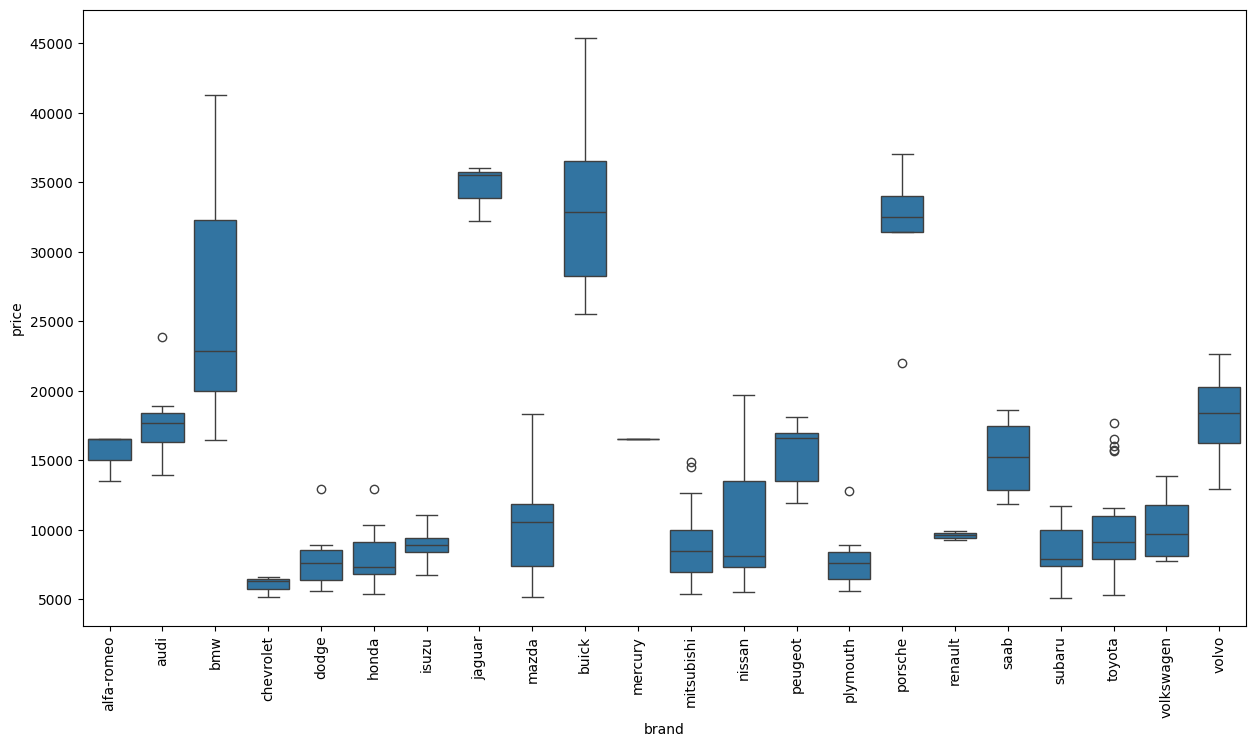

In [27]:
# some lines of code adapted from Gemini

plt.figure(figsize=(15, 8))
sns.boxplot(data=df, x='brand', y='price')
plt.xticks(rotation=90)
plt.show()

Using the above plot, we will set our median price at over $20,000 for the luxury group and under $20,000 for the mainstream group.

In [28]:
# code taken from Gemini
# define list of luxury manufacturers
luxury_makes = ['bmw', 'jaguar', 'buick', 'porsche']

# isolate prices and save to variables
luxury_prices = df[df['brand'].isin(luxury_makes)]['price']
mainstream_prices = df[~df['brand'].isin(luxury_makes)]['price']

# check descriptive statistics for luxury group
luxury_prices.describe()




count       24.000000
mean     30788.687500
std       7646.974625
min      16430.000000
25%      25305.250000
50%      31925.000000
75%      35662.500000
max      45400.000000
Name: price, dtype: float64

In [29]:
# check descriptive statistics for mainstream group
mainstream_prices.describe()

count      181.000000
mean     10954.680481
std       4306.778972
min       5118.000000
25%       7609.000000
50%       9538.000000
75%      13845.000000
max      23875.000000
Name: price, dtype: float64

In [30]:
# run the Mann-Whitney U test
pg.mwu(x=luxury_prices, y=mainstream_prices)

,U_val,alternative,p_val,RBC,CLES
MWU,4280.0,two-sided,1.185431e-14,0.970534,0.985267


### Hypothesis 4 Conclusion:

Null Hypothesis ($H_0$): There is no difference in price between luxury brands and mainstream brands.  
Alternative Hypothesis ($H_1$): There is a statistically significant difference in price between luxury brands and mainstream brands.  
Significance Threshold: $\alpha = 0.05$

Test Results:

Luxury vs. Mainstream:  
Mann-Whitney U ($U$): 4280.0  
p-value: $1.19 \times 10^{-14}$  
Common Language Effect Size (CLES): 0.985 (98.5%)  
Group Medians: Luxury = $31,925.00 | Mainstream = $9,538.00

Decision: The p-value ($1.19 \times 10^{-14}$) is much smaller than 0.05, and the CLES of 0.985 indicates a 98.5% probability that a randomly selected luxury car is more expensive than a mainstream car. Luxury cars have a much higher median price ($31,925.00) compared to mainstream cars ($9,538.00). Based on these results, we reject the null hypothesis and accept the alternative hypothesis that there is a statistically significant difference in price between luxury brands and mainstream brands.

NB: The U score belongs to the luxury group as it was passed first. Reversing the input order would not change the p_value or our final decision.

AI Usage Note: Generative AI was used for markdown and as a language and grammar tool in this insight summary.

## Conclusion

All tests confirmed that we rejected our 4 null hypotheses and accepted all 4 alternative hypotheses.

`engine_size`, `horsepower`, `curb_weight`, `car_length`, `drive-wheel` and brand type (luxury or mainstream) all had statistically significant effects on price. This means that these features are important for our client to understand and consider when entering the US car market.

## Next Steps

We will create a machine learning pipeline to predict car price.